# Optimisation différentiable : résolution par la méthode de Newton

**Niveau :** 4ᵉ année — Sciences des Données et Intelligence Artificielle  
**Outils :** NumPy, SymPy, Pandas, Matplotlib

---

## Plan du notebook

1. Introduction
2. Énoncé de l'exercice
3. Résolution mathématique
4. Implémentation Python
5. Résultats et visualisations
6. Interprétation et conclusion

## Partie 1 — Introduction

### 1.1 L'optimisation différentiable

L'optimisation différentiable consiste à chercher le minimum d'une fonction $f : \mathbb{R}^n \to \mathbb{R}$ dérivable :

$$\min_{x \in \mathbb{R}^n} f(x).$$

Le **gradient** $\nabla f(x)$ indique la direction de plus forte croissance de $f$ et la **matrice Hessienne** $H_f(x) = \nabla^2 f(x)$ décrit la courbure locale. Ces deux objets sont au cœur de l'entraînement des modèles de Machine Learning (régression logistique, réseaux de neurones, etc.).

### 1.2 Principe de la méthode de Newton

On approche $f$ au voisinage de l'itéré $x_k$ par son **développement de Taylor d'ordre 2** :

$$f(x_k + d) \approx f(x_k) + \nabla f(x_k)^\top d + \tfrac12\, d^\top H_f(x_k)\, d.$$

Si $H_f(x_k)$ est définie positive, ce modèle quadratique admet un unique minimum, obtenu en annulant son gradient en $d$ :

$$\nabla f(x_k) + H_f(x_k)\, d = 0.$$

### 1.3 Formule de Newton

$$\boxed{\,x_{k+1} = x_k - H_f(x_k)^{-1}\, \nabla f(x_k)\,}$$

En pratique, on n'inverse **pas** le Hessien : on résout le système linéaire
$$H_f(x_k)\, d_k = -\nabla f(x_k), \qquad x_{k+1} = x_k + d_k.$$

**Propriété clé :** près d'un minimum local $x^\*$ où $H_f(x^\*)$ est inversible, la convergence est **quadratique** : l'erreur est approximativement élevée au carré à chaque itération.

## Partie 2 — Énoncé de l'exercice

On considère la fonction de deux variables

$$f(x,y) = x^4 + y^4 - 4xy.$$

**Questions :**

1. Calculer le gradient et la matrice Hessienne de $f$.
2. Déterminer tous les points critiques et les classifier à l'aide du Hessien.
3. Appliquer la méthode de Newton à partir du point initial $x_0 = (2,\ 1{,}5)$ avec le critère d'arrêt $\|\nabla f(x_k)\|_2 < 10^{-10}$.
4. Présenter le tableau des itérations, la courbe de convergence et le chemin suivi sur les courbes de niveau.
5. Discuter les limites de la méthode (point initial, Hessien singulier ou indéfini).

**Pourquoi cette fonction ?** Elle est non quadratique (Newton a donc besoin de plusieurs itérations), possède deux minima globaux et un point selle : elle illustre à la fois la force et les limites de la méthode.

## Partie 3 — Résolution mathématique

### 3.1 Fonction objectif

$$f(x,y) = x^4 + y^4 - 4xy.$$

### 3.2 Gradient

$$\nabla f(x,y) = \begin{pmatrix} \dfrac{\partial f}{\partial x} \\[2mm] \dfrac{\partial f}{\partial y} \end{pmatrix} = \begin{pmatrix} 4x^3 - 4y \\ 4y^3 - 4x \end{pmatrix}.$$

### 3.3 Matrice Hessienne

$$H_f(x,y) = \begin{pmatrix} \dfrac{\partial^2 f}{\partial x^2} & \dfrac{\partial^2 f}{\partial x \partial y} \\[2mm] \dfrac{\partial^2 f}{\partial y \partial x} & \dfrac{\partial^2 f}{\partial y^2} \end{pmatrix} = \begin{pmatrix} 12x^2 & -4 \\ -4 & 12y^2 \end{pmatrix}.$$

Son déterminant est $\det H_f = 144\,x^2y^2 - 16$ et sa trace est $12(x^2+y^2)$.

### 3.4 Conditions d'optimalité

- **Condition nécessaire du premier ordre :** si $(x^\*,y^\*)$ est un minimum local, alors $\nabla f(x^\*,y^\*) = 0$.
- **Condition suffisante du second ordre :** si de plus $H_f(x^\*,y^\*)$ est définie positive, alors c'est un minimum local strict.

**Points critiques.** $\nabla f = 0 \iff y = x^3$ et $x = y^3$. En substituant : $x = x^9$, soit $x(x^8-1)=0$, donc $x \in \{0, 1, -1\}$ (dans $\mathbb{R}$). Les points critiques sont donc :

$$A = (0,0), \qquad B = (1,1), \qquad C = (-1,-1).$$

**Classification.**

| Point | $H_f$ | $\det H_f$ | Valeurs propres | Nature | $f$ |
|---|---|---|---|---|---|
| $A=(0,0)$ | $\begin{pmatrix}0&-4\\-4&0\end{pmatrix}$ | $-16$ | $\pm 4$ | point selle | $0$ |
| $B=(1,1)$ | $\begin{pmatrix}12&-4\\-4&12\end{pmatrix}$ | $128$ | $8,\ 16$ | minimum local strict | $-2$ |
| $C=(-1,-1)$ | $\begin{pmatrix}12&-4\\-4&12\end{pmatrix}$ | $128$ | $8,\ 16$ | minimum local strict | $-2$ |

Comme $f(x,y) \to +\infty$ quand $\|(x,y)\| \to \infty$, le minimum global existe : il vaut $-2$ et est atteint en $B$ et $C$ (ces vérifications sont refaites symboliquement avec SymPy ci-dessous).

### 3.5 Point initial

On prend $x_0 = (2,\ 1{,}5)$ : il est proche du minimum $B=(1,1)$ sans en être trop près, et le Hessien y est défini positif ($H_f(x_0) = \begin{pmatrix}48&-4\\-4&27\end{pmatrix}$, déterminant $1280 > 0$ et $48>0$).

### 3.6 Algorithme

1. Choisir $x_0$, la tolérance $\varepsilon = 10^{-10}$ et un nombre maximal d'itérations.
2. Pour $k = 0, 1, 2, \dots$ :
   1. calculer $g_k = \nabla f(x_k)$ ;
   2. si $\|g_k\|_2 < \varepsilon$, **arrêter** ;
   3. calculer $H_k = H_f(x_k)$ ;
   4. résoudre $H_k\, d_k = -g_k$ ;
   5. mettre à jour $x_{k+1} = x_k + d_k$.

## Partie 4 — Implémentation Python

### 4.1 Imports et réglages

In [1]:
import numpy as np
import sympy as sp
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.float_format", lambda v: f"{v:.10g}")
pd.set_option("display.width", 140)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})

### 4.2 Calcul symbolique du gradient et du Hessien (SymPy)

SymPy permet de **vérifier** les formules établies à la main en Partie 3.

In [2]:
x, y = sp.symbols("x y", real=True)
f_sym = x**4 + y**4 - 4*x*y

grad_sym = sp.Matrix([sp.diff(f_sym, x), sp.diff(f_sym, y)])   # 1. gradient
hess_sym = sp.hessian(f_sym, (x, y))                            # 2. Hessien

print("f(x,y)    =", f_sym)
sp.pprint(grad_sym)
sp.pprint(hess_sym)

f(x,y)    = x**4 - 4*x*y + y**4
⎡   3       ⎤
⎢4⋅x  - 4⋅y ⎥
⎢           ⎥
⎢          3⎥
⎣-4⋅x + 4⋅y ⎦
⎡    2       ⎤
⎢12⋅x    -4  ⎥
⎢            ⎥
⎢           2⎥
⎣ -4    12⋅y ⎦


### 4.3 Vérification des points critiques et de leur nature

In [3]:
sols = sp.solve(list(grad_sym), (x, y), dict=True)   # solutions réelles de grad f = 0
rows = []
for s in sols:
    H = hess_sym.subs(s)
    eigs = list(H.eigenvals().keys())
    nature = ("minimum local strict" if all(e > 0 for e in eigs)
              else "maximum local strict" if all(e < 0 for e in eigs)
              else "point selle")
    rows.append({"point": (s[x], s[y]), "f": f_sym.subs(s), "det(H)": H.det(),
                 "valeurs propres": eigs, "nature": nature})
pd.DataFrame(rows)

,point,f,det(H),valeurs propres,nature
0,"(-1, -1)",-2,128,"[16, 8]",minimum local strict
1,"(0, 0)",0,-16,"[-4, 4]",point selle
2,"(1, 1)",-2,128,"[16, 8]",minimum local strict


### 4.4 Passage en fonctions numériques

`lambdify` convertit les expressions symboliques en fonctions NumPy rapides.

In [4]:
f_num    = sp.lambdify((x, y), f_sym, "numpy")
grad_num = sp.lambdify((x, y), grad_sym, "numpy")
hess_num = sp.lambdify((x, y), hess_sym, "numpy")

def f(p):
    return float(f_num(p[0], p[1]))

def grad(p):
    return np.array(grad_num(p[0], p[1]), dtype=float).ravel()

def hess(p):
    return np.array(hess_num(p[0], p[1]), dtype=float)

# Test rapide au point initial
p0 = np.array([2.0, 1.5])
print("f(p0)    =", f(p0))
print("grad(p0) =", grad(p0))
print("hess(p0) =\n", hess(p0))

f(p0)    = 9.0625
grad(p0) = [26.   5.5]
hess(p0) =
 [[48. -4.]
 [-4. 27.]]


### 4.5 Algorithme de Newton

Chaque itération suit les étapes : **gradient → Hessien → système linéaire → mise à jour → test de convergence**.  
On utilise `numpy.linalg.solve` et non l'inverse explicite du Hessien (plus stable et moins coûteux).

In [5]:
def newton(p0, tol=1e-10, max_iter=50):
    # Méthode de Newton. Retourne l'historique des itérations (DataFrame).
    p = np.array(p0, dtype=float)
    historique = []

    for k in range(max_iter + 1):
        g = grad(p)                         # 1. gradient
        norme_g = np.linalg.norm(g)
        historique.append({"k": k, "x": p[0], "y": p[1], "f(x,y)": f(p),
                           "||grad||": norme_g})

        if norme_g < tol:                   # 5. critère de convergence
            break
        if k == max_iter:
            break

        H = hess(p)                         # 2. Hessien
        try:
            d = np.linalg.solve(H, -g)      # 3. résolution de H d = -g
        except np.linalg.LinAlgError:
            print(f"Hessien singulier à l'itération {k} : arrêt.")
            break
        p = p + d                           # 4. mise à jour

    return pd.DataFrame(historique)

## Partie 5 — Résultats et visualisations

### 5.1 Tableau des itérations

In [6]:
res = newton([2.0, 1.5], tol=1e-10)
res

,k,x,y,"f(x,y)",||grad||
0,0,2,1.5,9.0625,26.57536453
1,1,1.434375,1.2125,-0.5623343947,7.092604587
2,2,1.128672234,1.064240879,-1.899090383,1.525470158
3,3,1.016366209,1.008616425,-1.998491328,0.1696627663
4,4,1.000319602,1.00017812,-1.999999424,0.003240025309
5,5,1.000000127,1.000000074,-2,1.282750705e-06
6,6,1,1,-2,2.044740276e-13


### 5.2 Analyse de l'erreur et vitesse de convergence

Le minimum exact est $x^\* = (1,1)$. On calcule l'erreur $e_k = \|x_k - x^\*\|_2$ et le rapport $e_{k+1}/e_k^2$ : s'il reste borné, la convergence est **quadratique**.

In [7]:
x_star = np.array([1.0, 1.0])
res["erreur"] = np.linalg.norm(res[["x", "y"]].values - x_star, axis=1)
res["e_{k+1}/e_k^2"] = np.r_[res["erreur"].values[1:] / res["erreur"].values[:-1]**2, np.nan]
res[["k", "erreur", "e_{k+1}/e_k^2"]]

,k,erreur,e_{k+1}/e_k^2
0,0,1.118033989,0.3868543007
1,1,0.4835678759,0.6150301998
2,2,0.1438173646,0.8942337847
3,3,0.01849582579,1.069541823
4,4,0.0003658855214,1.096066917
5,5,1.467329057e-07,1.096578384
6,6,2.36099309e-14,NaN


In [8]:
p_final = res[["x", "y"]].values[-1]
print(f"Itérations effectuées : {len(res)-1}")
print(f"Point final           : ({p_final[0]:.12f}, {p_final[1]:.12f})")
print(f"f au point final      : {res['f(x,y)'].values[-1]:.12f}   (valeur théorique : -2)")
print(f"||grad|| final        : {res['||grad||'].values[-1]:.2e}")
print("Valeurs propres du Hessien final :", np.linalg.eigvalsh(hess(p_final)), "(attendu : 8 et 16)")

Itérations effectuées : 6
Point final           : (1.000000000000, 1.000000000000)
f au point final      : -2.000000000000   (valeur théorique : -2)
||grad|| final        : 2.04e-13
Valeurs propres du Hessien final : [ 8. 16.] (attendu : 8 et 16)


### 5.3 Courbe de convergence

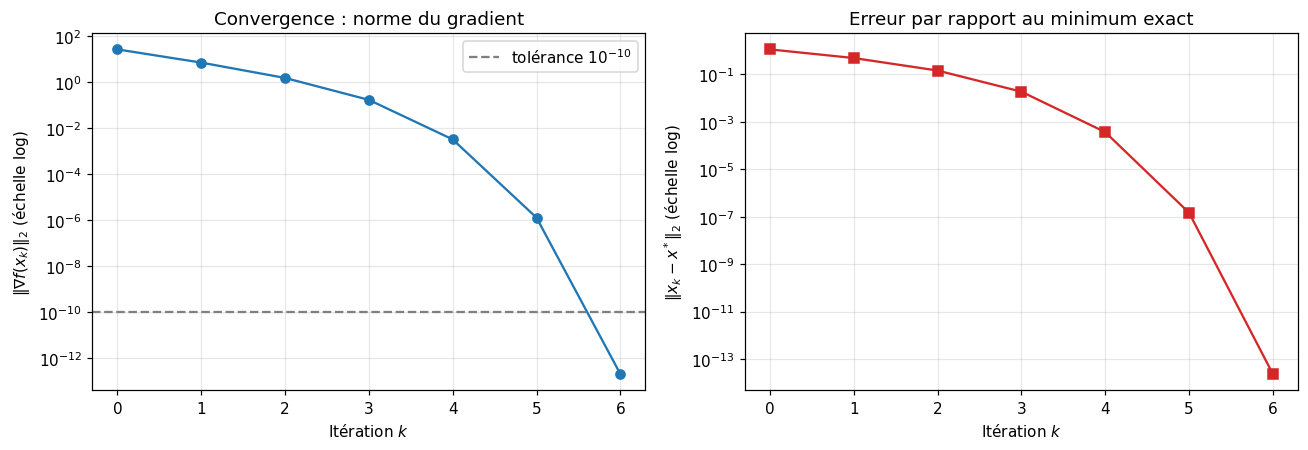

In [9]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4.2))

ax[0].semilogy(res["k"], res["||grad||"], "o-", color="tab:blue")
ax[0].axhline(1e-10, color="gray", ls="--", label="tolérance $10^{-10}$")
ax[0].set_title("Convergence : norme du gradient")
ax[0].set_xlabel("Itération $k$"); ax[0].set_ylabel(r"$\|\nabla f(x_k)\|_2$ (échelle log)")
ax[0].legend()

err = res["erreur"].clip(lower=1e-17)     # évite log(0)
ax[1].semilogy(res["k"], err, "s-", color="tab:red")
ax[1].set_title("Erreur par rapport au minimum exact")
ax[1].set_xlabel("Itération $k$"); ax[1].set_ylabel(r"$\|x_k - x^*\|_2$ (échelle log)")

plt.tight_layout(); plt.show()

### 5.4 Courbes de niveau et chemin suivi par Newton

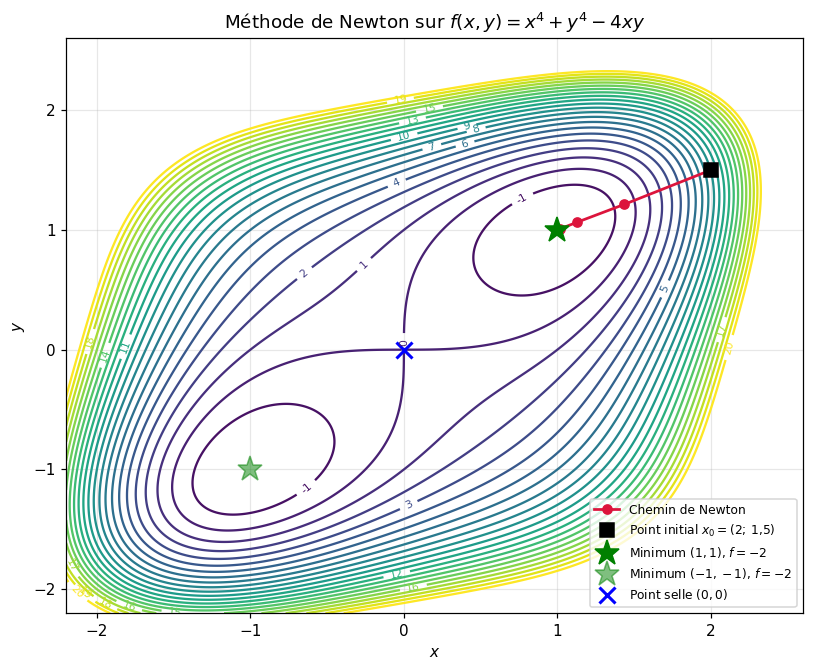

In [10]:
xs = np.linspace(-2.2, 2.6, 400)
ys = np.linspace(-2.2, 2.6, 400)
X, Y = np.meshgrid(xs, ys)
Z = f_num(X, Y)

fig, ax = plt.subplots(figsize=(7.5, 6.2))
cs = ax.contour(X, Y, Z, levels=np.linspace(-2, 20, 23), cmap="viridis")
ax.clabel(cs, inline=True, fontsize=7, fmt="%.0f")
ax.plot(res["x"], res["y"], "o-", color="crimson", lw=1.8, ms=6, label="Chemin de Newton")
ax.plot(*res[["x","y"]].values[0], "ks", ms=9, label="Point initial $x_0=(2;\\,1{,}5)$")
ax.plot(1, 1, "g*", ms=17, label="Minimum $(1,1)$, $f=-2$")
ax.plot(-1, -1, "g*", ms=17, alpha=0.5, label="Minimum $(-1,-1)$, $f=-2$")
ax.plot(0, 0, "bx", ms=11, mew=2, label="Point selle $(0,0)$")
ax.set_title("Méthode de Newton sur $f(x,y)=x^4+y^4-4xy$")
ax.set_xlabel("$x$"); ax.set_ylabel("$y$"); ax.legend(loc="lower right", fontsize=8)
plt.tight_layout(); plt.show()

### 5.5 Surface de $f$ (vue complémentaire)

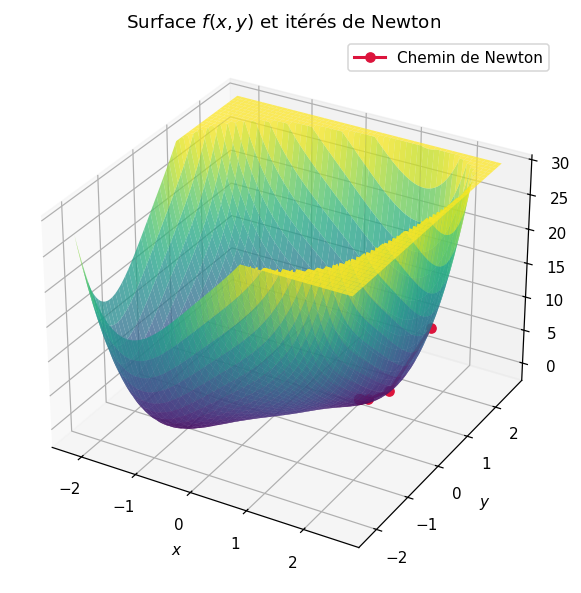

In [11]:
fig = plt.figure(figsize=(8, 5.5))
ax = fig.add_subplot(111, projection="3d")
Zc = np.clip(Z, -3, 30)
ax.plot_surface(X, Y, Zc, cmap="viridis", alpha=0.75, linewidth=0)
zpath = res["f(x,y)"].values
ax.plot(res["x"], res["y"], zpath, "o-", color="crimson", lw=2, label="Chemin de Newton")
ax.set_title("Surface $f(x,y)$ et itérés de Newton")
ax.set_xlabel("$x$"); ax.set_ylabel("$y$"); ax.set_zlabel("$f$")
ax.legend(); plt.tight_layout(); plt.show()

## Partie 6 — Interprétation et conclusion

### 6.1 Bilan de la convergence

In [12]:
print(f"Convergence atteinte en {len(res)-1} itérations.")
print(f"Minimum trouvé : x* = ({p_final[0]:.10f}, {p_final[1]:.10f}),  f(x*) = {res['f(x,y)'].values[-1]:.10f}")

Convergence atteinte en 6 itérations.
Minimum trouvé : x* = (1.0000000000, 1.0000000000),  f(x*) = -2.0000000000


Les résultats numériques sont **cohérents avec l'analyse mathématique** de la Partie 3 :

- l'algorithme converge vers $(1,1)$, l'un des deux minima globaux, où $f = -2$ ;
- à ce point, le gradient est nul (à la tolérance près) et le Hessien est défini positif (valeurs propres $8$ et $16$) : les conditions nécessaire et suffisante d'optimalité sont donc vérifiées ;
- la norme du gradient chute très rapidement et le rapport $e_{k+1}/e_k^2$ reste borné : c'est la signature de la **convergence quadratique**, caractéristique de Newton près d'un minimum non dégénéré.

### 6.2 Limites de la méthode

On illustre maintenant les trois limites principales à l'aide de la fonction `newton` déjà écrite.

**(a) Dépendance au point initial.** Selon $x_0$, Newton peut converger vers $(1,1)$, vers $(-1,-1)$, ou vers un point qui n'est pas un minimum.

In [13]:
departs = [(2.0, 1.5), (-1.5, -2.0), (0.3, 0.2), (-0.3, 0.1), (1.0, -1.0)]
lignes = []
for p0 in departs:
    r = newton(p0, tol=1e-10, max_iter=50)
    pf = r[["x", "y"]].values[-1]
    ev = np.linalg.eigvalsh(hess(pf))
    nature = "minimum" if np.all(ev > 1e-8) else ("point selle" if ev.min() < -1e-8 and ev.max() > 1e-8 else "dégénéré")
    lignes.append({"x0": p0, "itérations": len(r)-1,
                   "point final": tuple(np.round(pf, 6)),
                   "f final": round(r["f(x,y)"].values[-1], 6),
                   "||grad|| final": f"{r['||grad||'].values[-1]:.1e}",
                   "nature": nature})
pd.DataFrame(lignes)

,x0,itérations,point final,f final,||grad|| final,nature
0,"(2.0, 1.5)",6,"(1.0, 1.0)",-2,2.0e-13,minimum
1,"(-1.5, -2.0)",6,"(-1.0, -1.0)",-2,2.0e-13,minimum
2,"(0.3, 0.2)",4,"(0.0, 0.0)",0,2.5e-29,point selle
3,"(-0.3, 0.1)",4,"(-0.0, 0.0)",0,1.9e-30,point selle
4,"(1.0, -1.0)",5,"(0.0, -0.0)",0,4.1e-19,point selle


Le départ $(0{,}3;\ 0{,}2)$ est proche du point selle $(0,0)$ : Newton y converge, car la méthode cherche un **point critique** (gradient nul) et **non spécifiquement un minimum**. Dès que le Hessien n'est pas défini positif, la direction de Newton n'est plus nécessairement une direction de descente.

**(b) Hessien singulier.** Si $\det H_f(x_k) = 0$, le système $H_k d_k = -g_k$ n'a pas de solution unique. Ici $\det H_f = 144x^2y^2 - 16 = 0$ sur la courbe $|xy| = 1/3$ ; par exemple en $(x,y) = (1/\sqrt3,\ 1/\sqrt3)$.

In [14]:
p_sing = np.array([1/np.sqrt(3), 1/np.sqrt(3)])
H_s = hess(p_sing)
print("Hessien au point (1/sqrt3, 1/sqrt3) :\n", H_s)
print("déterminant         :", np.linalg.det(H_s))
print("valeurs propres     :", np.linalg.eigvalsh(H_s))
print("nombre de conditionnement :", np.linalg.cond(H_s))

Hessien au point (1/sqrt3, 1/sqrt3) :
 [[ 4. -4.]
 [-4.  4.]]
déterminant         : 7.105427357600985e-15
valeurs propres     : [8.8817842e-16 8.0000000e+00]
nombre de conditionnement : 1.0933836648235272e+16


Le déterminant est (numériquement) nul : le pas de Newton est mal défini ou énorme. À proximité d'une telle zone, la méthode devient instable.

**(c) Risque de non-convergence / coût.** Sans stratégie de globalisation, Newton peut diverger ou osciller si $x_0$ est loin de la solution. De plus, chaque itération demande le calcul du Hessien ($O(n^2)$ valeurs) et la résolution d'un système linéaire ($O(n^3)$), ce qui devient prohibitif en grande dimension, typiquement en Deep Learning.

### 6.3 Remèdes classiques

- **Recherche linéaire** (Armijo / Wolfe) ou **région de confiance** pour assurer la décroissance de $f$ ;
- **Régularisation** du Hessien : $H_k + \lambda I$ (méthode de Levenberg–Marquardt) pour garantir qu'il soit défini positif ;
- **Quasi-Newton** (BFGS, L-BFGS) qui évitent le calcul explicite du Hessien.

### 6.4 Conclusion

Appliquée à $f(x,y)=x^4+y^4-4xy$ depuis $x_0=(2;\,1{,}5)$, la méthode de Newton converge en quelques itérations vers le minimum global $(1,1)$ avec $f=-2$, en parfait accord avec la résolution analytique. Elle est extrêmement rapide près de la solution (convergence quadratique), mais reste **locale** : son comportement dépend du point initial et de la structure du Hessien, ce qui motive les variantes globalisées utilisées en pratique en Machine Learning.